<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/vector_calculus/Vector_Calculus_Differential.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Differential Vector Calculus

Differential operators describe how a field changes **locally**, at each point. Every section uses the same layout:

- **INPUT**: the field we start from
- **PROCESS**: the partial derivatives that are calculated
- **OUTPUT**: the resulting field and what it means

| # | Operator | Acts on | Produces | Measures |
|---|---|---|---|---|
| 1 | Gradient $\nabla f$ | scalar field | vector field | direction and rate of steepest ascent |
| 2 | Directional derivative $D_{\mathbf u} f$ | scalar field + direction | scalar | rate of change along $\mathbf u$ |
| 3 | Divergence $\nabla\cdot\mathbf F$ | vector field | scalar field | net outflow (source / sink) |
| 4 | Curl $\nabla\times\mathbf F$ | vector field | vector field (scalar in 2D) | local rotation |
| 5 | Laplacian $\nabla^2 f$ | scalar field | scalar field | difference from the average of neighbours |
| 6 | Identities | | | how the operators combine |

Sections 1, 2, 5 and 6 share one example scalar field, a hill at $(1, 0)$ and a valley at $(-1, 0)$:

$$f(x, y) = e^{-\left((x-1)^2 + y^2\right)} - e^{-\left((x+1)^2 + y^2\right)}$$

## 1. Gradient

$$\nabla f = \left(\frac{\partial f}{\partial x},\ \frac{\partial f}{\partial y}\right)$$

The gradient turns a scalar field into a vector field. At every point it:
- points in the direction of **steepest ascent**,
- has length equal to the slope in that direction,
- is **perpendicular to the level curves** of $f$,
- is zero at peaks, pits and saddle points.

--- GRADIENT ---
max |df/dx numeric - exact| = 1.41e-02
max |df/dy numeric - exact| = 6.35e-03
max |grad f|                = 1.4666


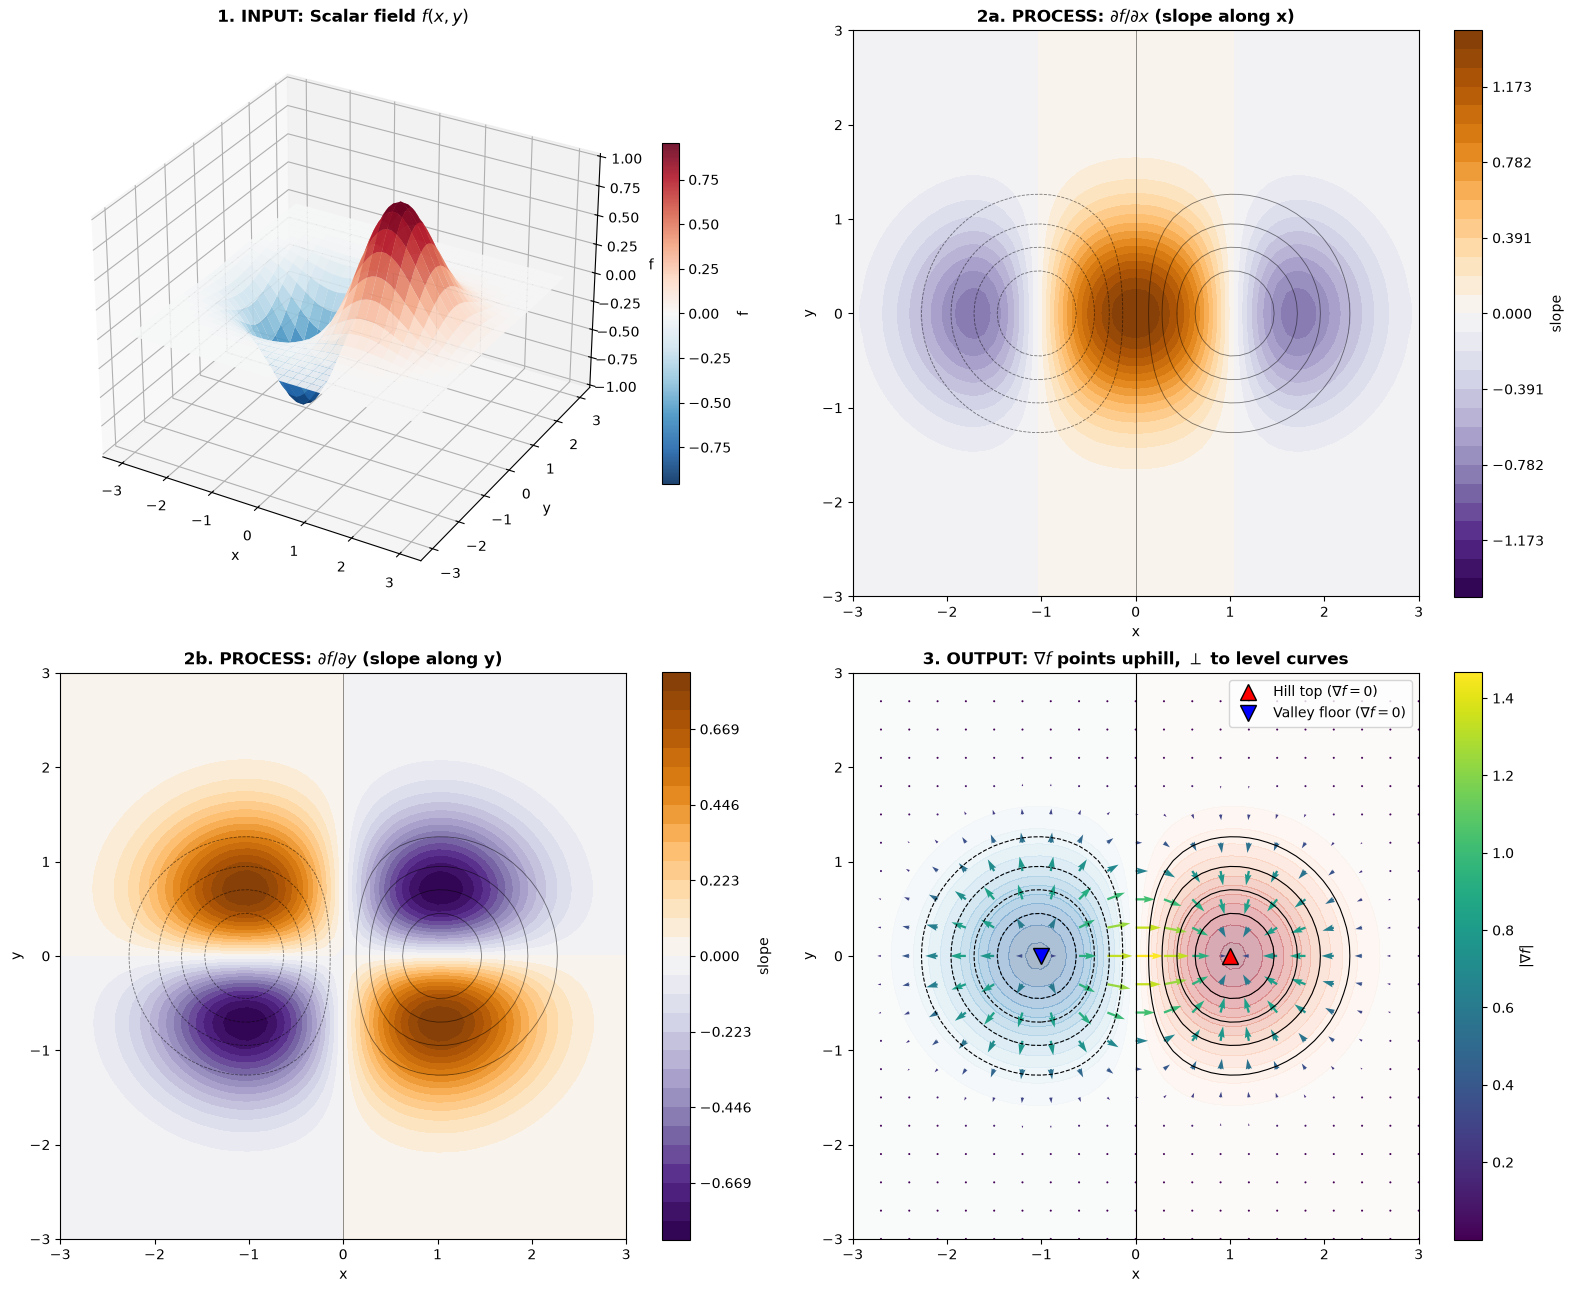

In [1]:
# 1. GRADIENT: grad f = (df/dx, df/dy)
# INPUT: scalar field f  ->  PROCESS: partial derivatives  ->  OUTPUT: vector field grad f

import numpy as np
import matplotlib.pyplot as plt

# --- INPUT: scalar field f(x, y), a hill at (1, 0) and a valley at (-1, 0) ---
x = np.linspace(-3, 3, 61)
y = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(x, y)
hill = np.exp(-((X - 1)**2 + Y**2))
valley = np.exp(-((X + 1)**2 + Y**2))
f = hill - valley

# --- PROCESS: partial derivatives by central differences (axis 0 is y, axis 1 is x) ---
df_dy, df_dx = np.gradient(f, y, x)

# Analytical partial derivatives, to verify the numerical ones
df_dx_exact = -2 * (X - 1) * hill + 2 * (X + 1) * valley
df_dy_exact = -2 * Y * hill + 2 * Y * valley

print("--- GRADIENT ---")
print(f"max |df/dx numeric - exact| = {np.max(np.abs(df_dx - df_dx_exact)):.2e}")
print(f"max |df/dy numeric - exact| = {np.max(np.abs(df_dy - df_dy_exact)):.2e}")
print(f"max |grad f|                = {np.max(np.hypot(df_dx, df_dy)):.4f}")

# --- Visualization ---
fig = plt.figure(figsize=(16, 13))

# Panel 1: INPUT
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
surf = ax1.plot_surface(X, Y, f, cmap='RdBu_r', edgecolor='none', alpha=0.9)
ax1.set_title('1. INPUT: Scalar field $f(x, y)$', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f')
ax1.view_init(elev=30, azim=-60)
fig.colorbar(surf, ax=ax1, shrink=0.6, label='f')

# Panels 2a, 2b: PROCESS (one partial derivative each)
process = [
    (2, df_dx, r'2a. PROCESS: $\partial f/\partial x$ (slope along x)'),
    (3, df_dy, r'2b. PROCESS: $\partial f/\partial y$ (slope along y)'),
]
for idx, comp, title in process:
    ax = fig.add_subplot(2, 2, idx)
    vmax = np.abs(comp).max()
    cf = ax.contourf(X, Y, comp, levels=np.linspace(-vmax, vmax, 31), cmap='PuOr_r')
    ax.contour(X, Y, f, levels=10, colors='k', linewidths=0.6, alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal')
    fig.colorbar(cf, ax=ax, label='slope')

# Panel 3: OUTPUT (gradient vectors over level curves)
ax4 = fig.add_subplot(2, 2, 4)
ax4.contourf(X, Y, f, levels=30, cmap='RdBu_r', alpha=0.35)
ax4.contour(X, Y, f, levels=12, colors='k', linewidths=0.8)
s = 3
magnitude = np.hypot(df_dx, df_dy)
q = ax4.quiver(X[::s, ::s], Y[::s, ::s], df_dx[::s, ::s], df_dy[::s, ::s], magnitude[::s, ::s],
               cmap='viridis', scale_units='xy', scale=5, width=0.004)
ax4.plot(1, 0, '^', color='red', ms=12, mec='k', label=r'Hill top ($\nabla f = 0$)')
ax4.plot(-1, 0, 'v', color='blue', ms=12, mec='k', label=r'Valley floor ($\nabla f = 0$)')
ax4.set_title(r'3. OUTPUT: $\nabla f$ points uphill, $\perp$ to level curves', fontsize=12, fontweight='bold')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_aspect('equal')
ax4.legend(loc='upper right')
fig.colorbar(q, ax=ax4, label=r'$|\nabla f|$')

plt.tight_layout()
plt.show()

## 2. Directional Derivative

$$D_{\mathbf u} f = \nabla f \cdot \mathbf u = |\nabla f|\cos\theta, \qquad |\mathbf u| = 1$$

The rate of change of $f$ when moving from a point in the direction of the unit vector $\mathbf u$. It is the **projection of the gradient onto $\mathbf u$**, so:
- it is largest, $|\nabla f|$, when $\mathbf u$ points along $\nabla f$ ($\theta = 0$),
- it is zero when $\mathbf u$ runs along the level curve ($\theta = \pm 90^\circ$),
- it is smallest, $-|\nabla f|$, when $\mathbf u$ points against $\nabla f$.

--- DIRECTIONAL DERIVATIVE ---
p = [0.4 0.7], u = (0.940, 0.342)
grad f(p) = (0.7545, -0.4776),  |grad f| = 0.8930
angle between grad f and u = 52.3 deg
D_u f = grad f . u          = 0.545678
finite difference           = 0.545678


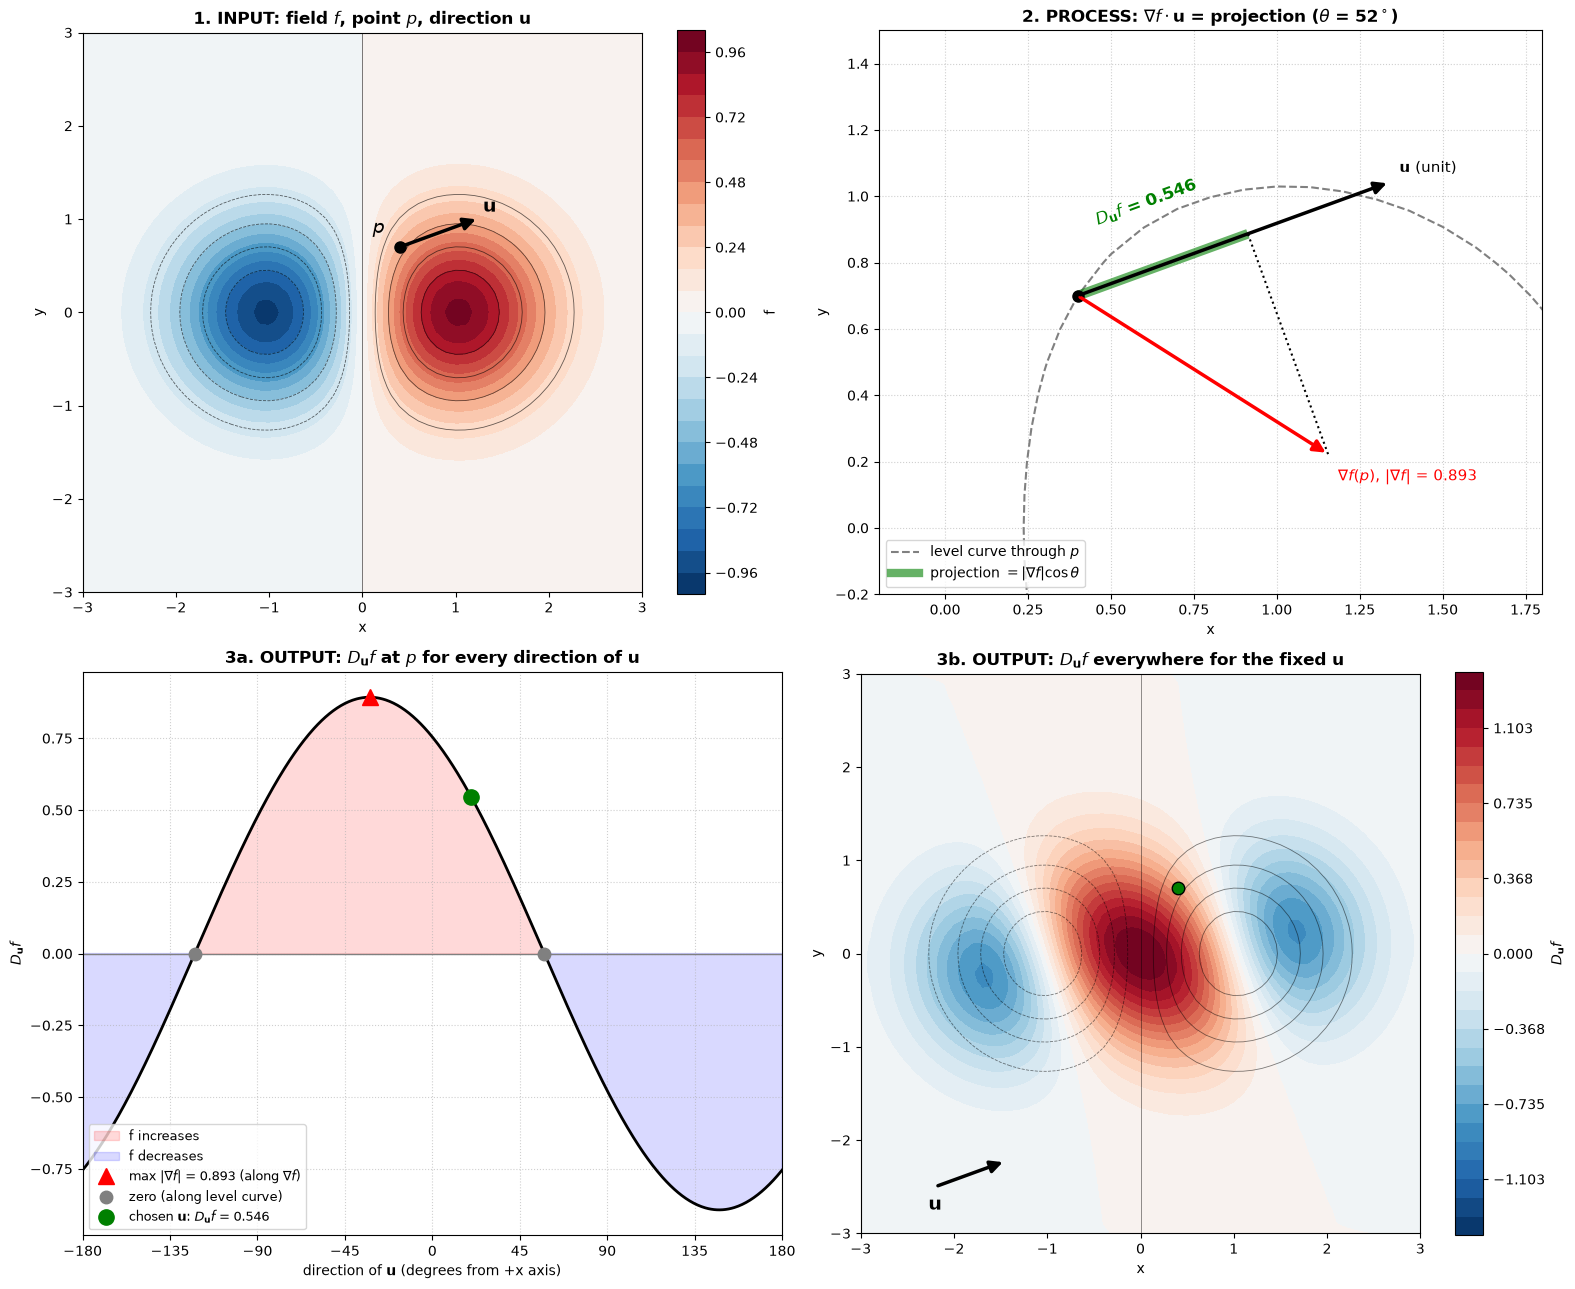

In [2]:
# 2. DIRECTIONAL DERIVATIVE: D_u f = grad f . u
# INPUT: f, point p, direction u  ->  PROCESS: project grad f onto u  ->  OUTPUT: D_u f

import numpy as np
import matplotlib.pyplot as plt


def f_func(x, y):
    return np.exp(-((x - 1)**2 + y**2)) - np.exp(-((x + 1)**2 + y**2))


def grad_f(x, y):
    hill = np.exp(-((x - 1)**2 + y**2))
    valley = np.exp(-((x + 1)**2 + y**2))
    return np.array([-2 * (x - 1) * hill + 2 * (x + 1) * valley,
                     -2 * y * hill + 2 * y * valley])


# --- INPUT: scalar field, a point p and a unit direction u ---
x = np.linspace(-3, 3, 61)
y = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(x, y)
f = f_func(X, Y)

p = np.array([0.4, 0.7])
theta_u = np.deg2rad(20)
u = np.array([np.cos(theta_u), np.sin(theta_u)])

# --- PROCESS: gradient at p, then dot product with u ---
g = grad_f(*p)
g_norm = np.linalg.norm(g)
D_u = g @ u
theta_between = np.degrees(np.arccos(D_u / g_norm))

# Check against a finite difference: (f(p + h u) - f(p - h u)) / 2h
h = 1e-5
D_u_fd = (f_func(*(p + h * u)) - f_func(*(p - h * u))) / (2 * h)

print("--- DIRECTIONAL DERIVATIVE ---")
print(f"p = {p}, u = ({u[0]:.3f}, {u[1]:.3f})")
print(f"grad f(p) = ({g[0]:.4f}, {g[1]:.4f}),  |grad f| = {g_norm:.4f}")
print(f"angle between grad f and u = {theta_between:.1f} deg")
print(f"D_u f = grad f . u          = {D_u:.6f}")
print(f"finite difference           = {D_u_fd:.6f}")

# D_u f for every direction around p, and for fixed u at every point
thetas = np.linspace(-np.pi, np.pi, 721)
D_theta = g[0] * np.cos(thetas) + g[1] * np.sin(thetas)
theta_grad = np.arctan2(g[1], g[0])

df_dy, df_dx = np.gradient(f, y, x)
D_u_map = df_dx * u[0] + df_dy * u[1]

# --- Visualization ---
fig = plt.figure(figsize=(16, 13))
arrow = dict(arrowstyle='-|>', lw=2.5, mutation_scale=18)

# Panel 1: INPUT
ax1 = fig.add_subplot(2, 2, 1)
cf1 = ax1.contourf(X, Y, f, levels=30, cmap='RdBu_r')
ax1.contour(X, Y, f, levels=12, colors='k', linewidths=0.6, alpha=0.6)
ax1.annotate('', xy=p + 0.9 * u, xytext=p, arrowprops=dict(arrow, color='k'))
ax1.plot(*p, 'ko', ms=8)
ax1.text(p[0] - 0.15, p[1] + 0.15, '$p$', fontsize=14, ha='right')
ax1.text(*(p + 0.95 * u), r'$\mathbf{u}$', fontsize=14, va='bottom')
ax1.set_title(r'1. INPUT: field $f$, point $p$, direction $\mathbf{u}$', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_aspect('equal')
fig.colorbar(cf1, ax=ax1, label='f')

# Panel 2: PROCESS (projection of grad f onto u, zoomed around p)
ax2 = fig.add_subplot(2, 2, 2)
ax2.contour(X, Y, f, levels=[f_func(*p)], colors='gray', linestyles='--', linewidths=1.5)
proj = p + D_u * u
ax2.annotate('', xy=p + g, xytext=p, arrowprops=dict(arrow, color='red'))
ax2.annotate('', xy=p + u, xytext=p, arrowprops=dict(arrow, color='k'))
ax2.plot([p[0], proj[0]], [p[1], proj[1]], color='green', lw=7, alpha=0.6, solid_capstyle='butt')
ax2.plot([p[0] + g[0], proj[0]], [p[1] + g[1], proj[1]], 'k:', lw=1.5)
ax2.plot(*p, 'ko', ms=8)
ax2.text(*(p + g + [0.03, -0.08]), rf'$\nabla f(p)$, $|\nabla f|$ = {g_norm:.3f}', color='red', fontsize=11)
ax2.text(*(p + u + [0.03, 0.03]), r'$\mathbf{u}$ (unit)', fontsize=11)
ax2.text(*(p + 0.5 * D_u * u + [-0.05, 0.12]), rf'$D_\mathbf{{u}}f$ = {D_u:.3f}', color='green',
         fontsize=12, fontweight='bold', rotation=np.degrees(theta_u), ha='center')
ax2.plot([], [], 'gray', ls='--', label='level curve through $p$')
ax2.plot([], [], 'green', lw=6, alpha=0.6, label=r'projection $= |\nabla f|\cos\theta$')
ax2.set_xlim(p[0] - 0.6, p[0] + 1.4)
ax2.set_ylim(p[1] - 0.9, p[1] + 0.8)
ax2.set_title(rf'2. PROCESS: $\nabla f\cdot\mathbf{{u}}$ = projection ($\theta$ = {theta_between:.0f}$^\circ$)',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_aspect('equal')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='lower left')

# Panel 3: OUTPUT (D_u f at p for every direction)
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(np.degrees(thetas), D_theta, 'k-', lw=2)
ax3.axhline(0, color='gray', lw=1)
ax3.fill_between(np.degrees(thetas), D_theta, 0, where=D_theta >= 0, color='red', alpha=0.15, label='f increases')
ax3.fill_between(np.degrees(thetas), D_theta, 0, where=D_theta < 0, color='blue', alpha=0.15, label='f decreases')
ax3.plot(np.degrees(theta_grad), g_norm, 'r^', ms=11, label=rf'max $|\nabla f|$ = {g_norm:.3f} (along $\nabla f$)')
for sgn in (-1, 1):
    t0 = np.degrees(np.arctan2(np.sin(theta_grad + sgn * np.pi / 2), np.cos(theta_grad + sgn * np.pi / 2)))
    ax3.plot(t0, 0, 'o', color='gray', ms=9, label='zero (along level curve)' if sgn == 1 else None)
ax3.plot(np.degrees(theta_u), D_u, 'go', ms=11, label=rf'chosen $\mathbf{{u}}$: $D_\mathbf{{u}}f$ = {D_u:.3f}')
ax3.set_xlim(-180, 180)
ax3.set_xticks(range(-180, 181, 45))
ax3.set_title(r'3a. OUTPUT: $D_\mathbf{u}f$ at $p$ for every direction of $\mathbf{u}$', fontsize=12, fontweight='bold')
ax3.set_xlabel(r'direction of $\mathbf{u}$ (degrees from +x axis)')
ax3.set_ylabel(r'$D_\mathbf{u} f$')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc='lower left', fontsize=9)

# Panel 4: OUTPUT (D_u f for the fixed u at every point)
ax4 = fig.add_subplot(2, 2, 4)
vmax = np.abs(D_u_map).max()
cf4 = ax4.contourf(X, Y, D_u_map, levels=np.linspace(-vmax, vmax, 31), cmap='RdBu_r')
ax4.contour(X, Y, f, levels=12, colors='k', linewidths=0.6, alpha=0.5)
ax4.annotate('', xy=(-2.2 + 0.8 * u[0], -2.5 + 0.8 * u[1]), xytext=(-2.2, -2.5),
             arrowprops=dict(arrow, color='k'))
ax4.text(-2.2, -2.75, r'$\mathbf{u}$', fontsize=14, ha='center')
ax4.plot(*p, 'go', ms=9, mec='k')
ax4.set_title(r'3b. OUTPUT: $D_\mathbf{u}f$ everywhere for the fixed $\mathbf{u}$', fontsize=12, fontweight='bold')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_aspect('equal')
fig.colorbar(cf4, ax=ax4, label=r'$D_\mathbf{u} f$')

plt.tight_layout()
plt.show()

## 3. Divergence

$$\nabla\cdot\mathbf F = \frac{\partial P}{\partial x} + \frac{\partial Q}{\partial y}, \qquad \mathbf F = (P, Q)$$

The net outflow per unit area at a point:
- $\nabla\cdot\mathbf F > 0$: a **source** (more flows out than in),
- $\nabla\cdot\mathbf F < 0$: a **sink**,
- $\nabla\cdot\mathbf F = 0$: incompressible flow.

Example: $\mathbf F = (\sin x,\ \sin y)$, so $\nabla\cdot\mathbf F = \cos x + \cos y$.

--- DIVERGENCE ---
max |div F numeric - exact| = 7.34e-02
div F at source (0, 0)      = +2.0
div F at sink (pi, pi)      = -2.0


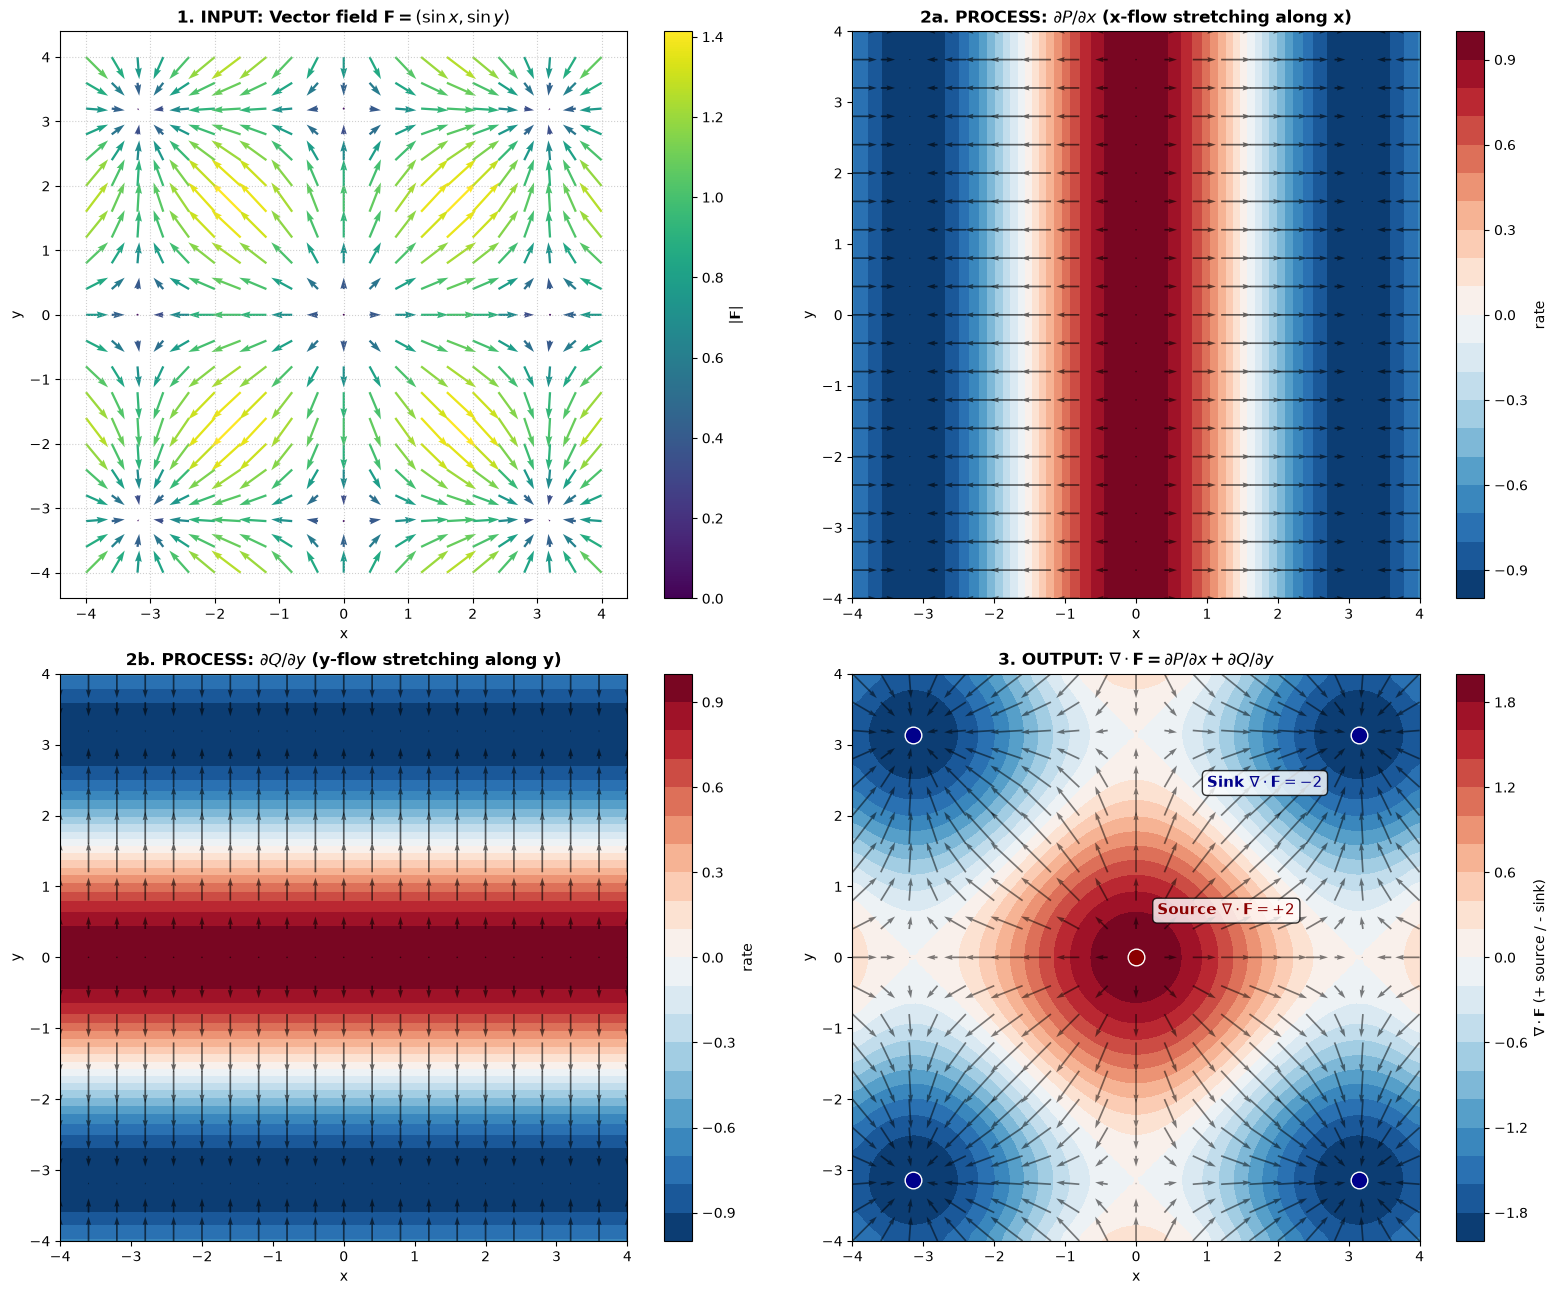

In [3]:
# 3. DIVERGENCE: div F = dP/dx + dQ/dy
# INPUT: vector field F = (P, Q)  ->  PROCESS: dP/dx and dQ/dy  ->  OUTPUT: scalar field div F

import numpy as np
import matplotlib.pyplot as plt

# --- INPUT: vector field F = (sin x, sin y) ---
x = np.linspace(-4, 4, 81)
y = np.linspace(-4, 4, 81)
X, Y = np.meshgrid(x, y)
P = np.sin(X)
Q = np.sin(Y)

# --- PROCESS: the two "stretching" partial derivatives ---
dP_dy, dP_dx = np.gradient(P, y, x)
dQ_dy, dQ_dx = np.gradient(Q, y, x)
div_F = dP_dx + dQ_dy

div_exact = np.cos(X) + np.cos(Y)
print("--- DIVERGENCE ---")
print(f"max |div F numeric - exact| = {np.max(np.abs(div_F - div_exact)):.2e}")
print(f"div F at source (0, 0)      = {np.cos(0) + np.cos(0):+.1f}")
print(f"div F at sink (pi, pi)      = {np.cos(np.pi) + np.cos(np.pi):+.1f}")

# --- Visualization ---
fig = plt.figure(figsize=(16, 13))
s = 4
Xs, Ys = X[::s, ::s], Y[::s, ::s]

# Panel 1: INPUT
ax1 = fig.add_subplot(2, 2, 1)
magnitude = np.hypot(P, Q)
q1 = ax1.quiver(Xs, Ys, P[::s, ::s], Q[::s, ::s], magnitude[::s, ::s], cmap='viridis',
                scale_units='xy', scale=2.2, width=0.004)
ax1.set_title(r'1. INPUT: Vector field $\mathbf{F} = (\sin x, \sin y)$', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_aspect('equal')
ax1.grid(True, linestyle=':', alpha=0.6)
fig.colorbar(q1, ax=ax1, label=r'$|\mathbf{F}|$')

# Panels 2a, 2b: PROCESS (each component's change along its own direction)
process = [
    (2, dP_dx, P, np.zeros_like(Q), r'2a. PROCESS: $\partial P/\partial x$ (x-flow stretching along x)'),
    (3, dQ_dy, np.zeros_like(P), Q, r'2b. PROCESS: $\partial Q/\partial y$ (y-flow stretching along y)'),
]
for idx, comp, U, V, title in process:
    ax = fig.add_subplot(2, 2, idx)
    cf = ax.contourf(X, Y, comp, levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    ax.quiver(Xs, Ys, U[::s, ::s], V[::s, ::s], color='k', alpha=0.6, scale_units='xy', scale=2.2, width=0.003)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal')
    fig.colorbar(cf, ax=ax, label='rate')

# Panel 3: OUTPUT
ax4 = fig.add_subplot(2, 2, 4)
cf4 = ax4.contourf(X, Y, div_F, levels=np.linspace(-2, 2, 21), cmap='RdBu_r')
ax4.quiver(Xs, Ys, P[::s, ::s], Q[::s, ::s], color='k', alpha=0.5, scale_units='xy', scale=2.2, width=0.003)
ax4.plot(0, 0, 'o', color='darkred', ms=12, mec='w')
ax4.annotate(r'Source $\nabla\cdot\mathbf{F} = +2$', xy=(0, 0), xytext=(0.3, 0.6), color='darkred',
             fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', fc='w', alpha=0.8))
for sx in (-np.pi, np.pi):
    for sy in (-np.pi, np.pi):
        ax4.plot(sx, sy, 'o', color='darkblue', ms=12, mec='w')
ax4.annotate(r'Sink $\nabla\cdot\mathbf{F} = -2$', xy=(np.pi, np.pi), xytext=(1.0, 2.4), color='darkblue',
             fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', fc='w', alpha=0.8))
ax4.set_title(r'3. OUTPUT: $\nabla\cdot\mathbf{F} = \partial P/\partial x + \partial Q/\partial y$',
              fontsize=12, fontweight='bold')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_aspect('equal')
fig.colorbar(cf4, ax=ax4, label=r'$\nabla\cdot\mathbf{F}$ (+ source / - sink)')

plt.tight_layout()
plt.show()

## 4. Curl

$$\nabla\times\mathbf F = \left(\frac{\partial Q}{\partial x} - \frac{\partial P}{\partial y}\right)\hat{\mathbf k} \qquad \text{(2D field } \mathbf F = (P, Q)\text{)}$$

The local rotation of a field. A small paddle wheel placed in the flow spins **counter-clockwise** where the curl is positive and **clockwise** where it is negative. In 3D the curl is a vector along the rotation axis (right-hand rule); for a 2D field it points along $z$.

Example: a counter-clockwise vortex at $(-1, 0)$ and a clockwise vortex at $(1, 0)$. For one vortex $\mathbf F = (-y, x)\,e^{-r^2}$ the curl is $2(1 - r^2)\,e^{-r^2}$: strong spin in the core, and a weak ring of opposite spin for $r > 1$, where the flow slows down with distance (shear).

--- CURL ---
max |curl numeric - exact| = 1.96e-02
curl at CCW vortex (-1, 0) = +2.110
curl at CW  vortex ( 1, 0) = -2.110


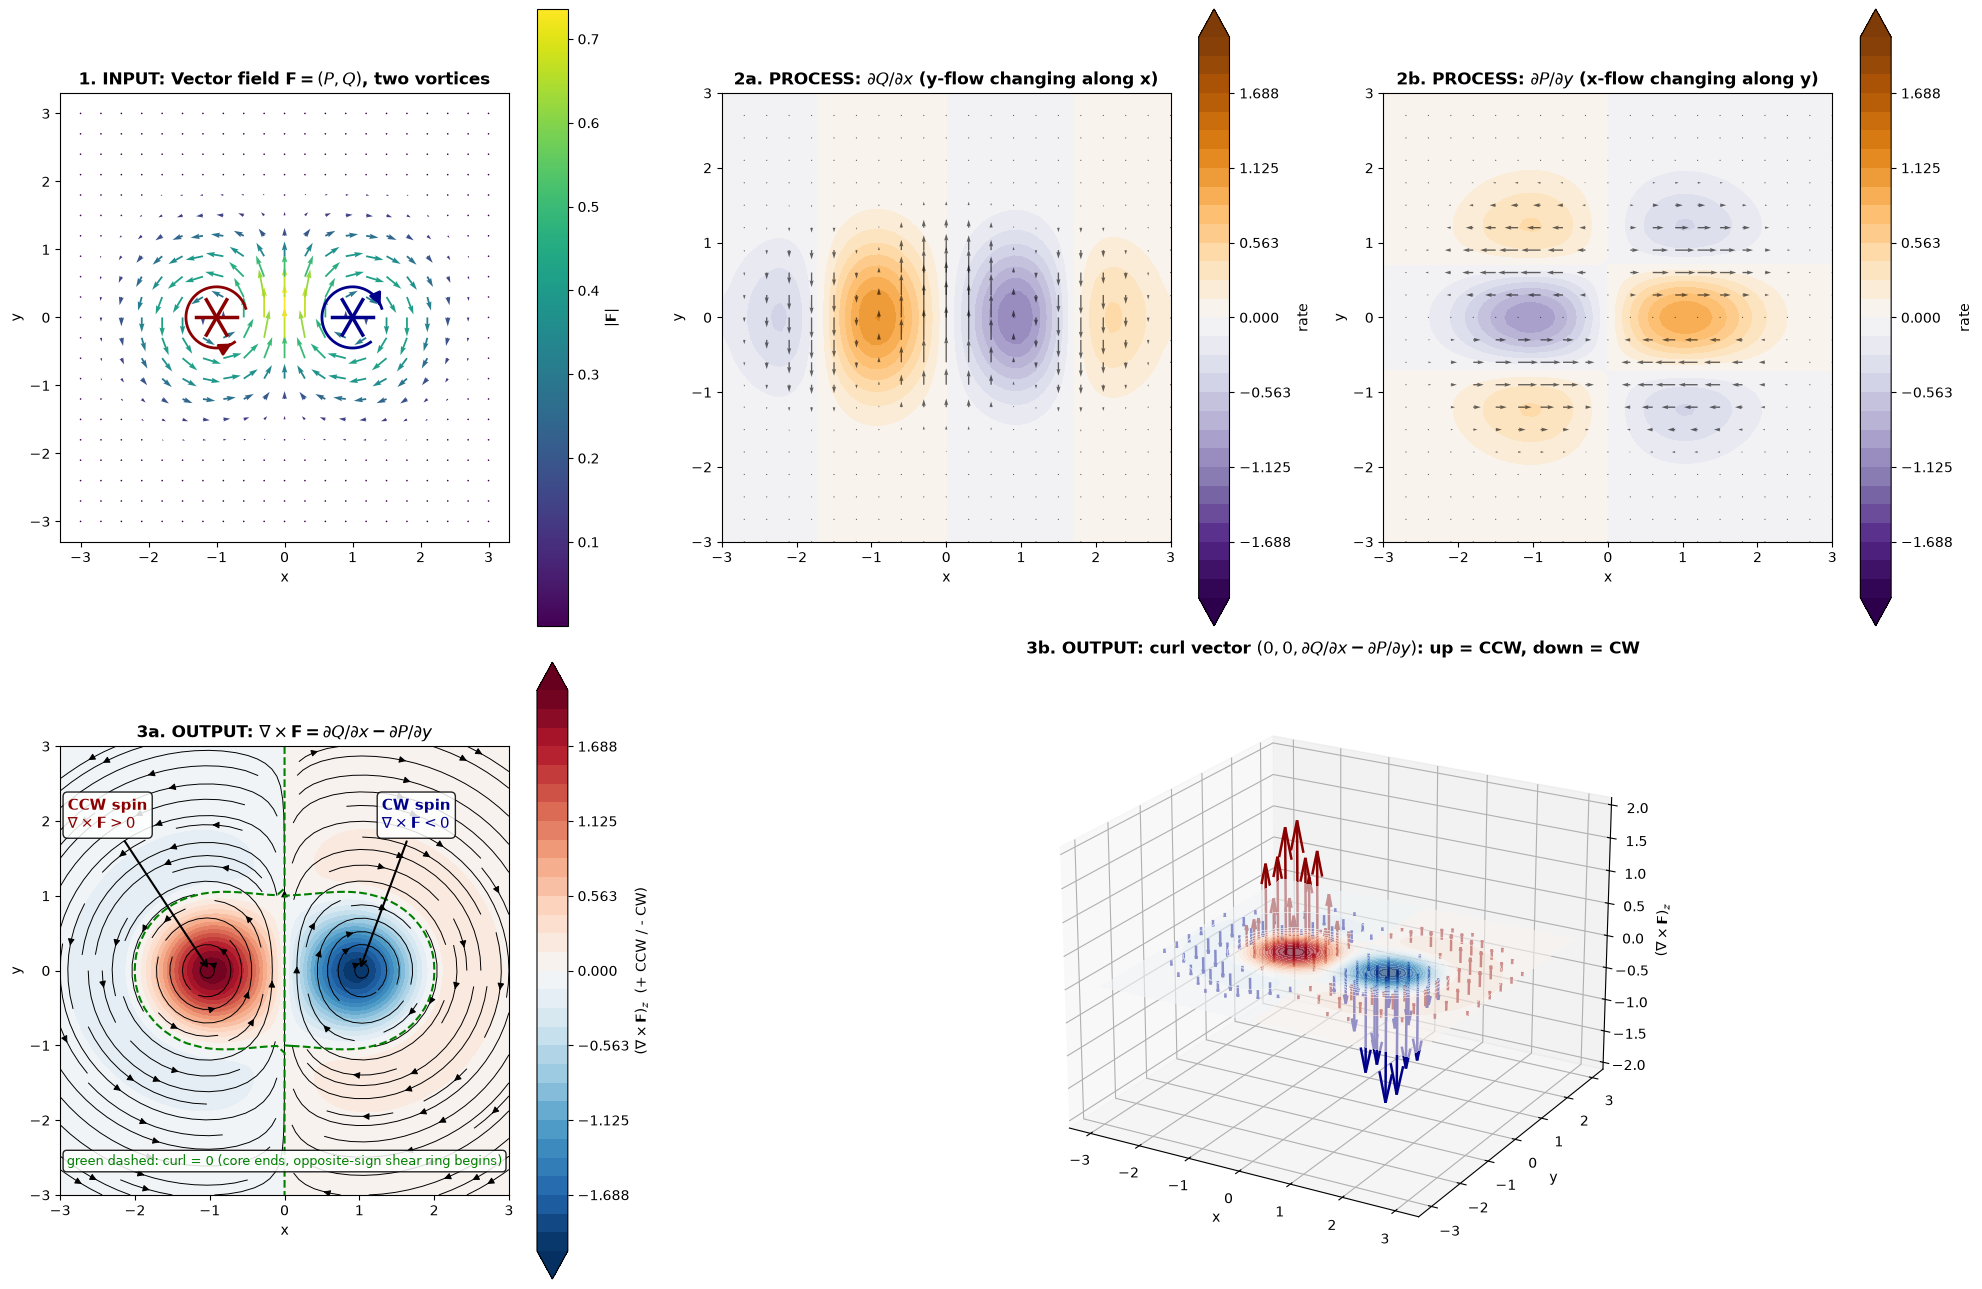

In [4]:
# 4. CURL: curl F = dQ/dx - dP/dy  (z-component for a 2D field F = (P, Q))
# INPUT: vector field F  ->  PROCESS: dQ/dx and dP/dy  ->  OUTPUT: curl (scalar map and z-vectors)

import numpy as np
import matplotlib.pyplot as plt


def paddle_wheel(ax, center, ccw, color='k'):
    # Schematic paddle wheel with an arrow showing which way it spins.
    cx, cy = center
    for a in np.linspace(0, np.pi, 3, endpoint=False):
        ax.plot([cx - 0.3 * np.cos(a), cx + 0.3 * np.cos(a)], [cy - 0.3 * np.sin(a), cy + 0.3 * np.sin(a)],
                color=color, lw=2.5, zorder=5)
    t = np.linspace(0.3, 1.7 * np.pi, 60)
    if not ccw:
        t = t[::-1]
    ax.plot(cx + 0.45 * np.cos(t), cy + 0.45 * np.sin(t), color=color, lw=2, zorder=5)
    ax.annotate('', xy=(cx + 0.45 * np.cos(t[-1]), cy + 0.45 * np.sin(t[-1])),
                xytext=(cx + 0.45 * np.cos(t[-4]), cy + 0.45 * np.sin(t[-4])),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2, mutation_scale=18), zorder=5)


# --- INPUT: counter-clockwise vortex at (-1, 0) and clockwise vortex at (1, 0) ---
x = np.linspace(-3, 3, 61)
y = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(x, y)
g1 = np.exp(-((X + 1)**2 + Y**2))
g2 = np.exp(-((X - 1)**2 + Y**2))
P = -Y * g1 + Y * g2
Q = (X + 1) * g1 - (X - 1) * g2

# --- PROCESS: the two cross partial derivatives ---
dP_dy, dP_dx = np.gradient(P, y, x)
dQ_dy, dQ_dx = np.gradient(Q, y, x)
curl_z = dQ_dx - dP_dy

r1 = (X + 1)**2 + Y**2
r2 = (X - 1)**2 + Y**2
curl_exact = 2 * (1 - r1) * g1 - 2 * (1 - r2) * g2

print("--- CURL ---")
print(f"max |curl numeric - exact| = {np.max(np.abs(curl_z - curl_exact)):.2e}")
print(f"curl at CCW vortex (-1, 0) = {curl_exact[30, 20]:+.3f}")
print(f"curl at CW  vortex ( 1, 0) = {curl_exact[30, 40]:+.3f}")

# --- Visualization ---
fig = plt.figure(figsize=(20, 13))
gs = fig.add_gridspec(2, 3)
s = 3
Xs, Ys = X[::s, ::s], Y[::s, ::s]

# Panel 1: INPUT
ax1 = fig.add_subplot(gs[0, 0])
speed = np.hypot(P, Q)
q1 = ax1.quiver(Xs, Ys, P[::s, ::s], Q[::s, ::s], speed[::s, ::s], cmap='viridis',
                scale_units='xy', scale=1.5, width=0.004)
paddle_wheel(ax1, (-1, 0), ccw=True, color='darkred')
paddle_wheel(ax1, (1, 0), ccw=False, color='darkblue')
ax1.set_title(r'1. INPUT: Vector field $\mathbf{F} = (P, Q)$, two vortices', fontsize=12, fontweight='bold')
fig.colorbar(q1, ax=ax1, label=r'$|\mathbf{F}|$')

# Panels 2a, 2b: PROCESS
vmax = np.abs(curl_exact).max()
levels = np.linspace(-vmax, vmax, 31)
process = [
    (gs[0, 1], dQ_dx, np.zeros_like(P), Q, r'2a. PROCESS: $\partial Q/\partial x$ (y-flow changing along x)'),
    (gs[0, 2], dP_dy, P, np.zeros_like(Q), r'2b. PROCESS: $\partial P/\partial y$ (x-flow changing along y)'),
]
for spec, comp, U, V, title in process:
    ax = fig.add_subplot(spec)
    cf = ax.contourf(X, Y, comp, levels=levels, cmap='PuOr_r', extend='both')
    ax.quiver(Xs, Ys, U[::s, ::s], V[::s, ::s], color='k', alpha=0.6, scale_units='xy', scale=1.5, width=0.003)
    ax.set_title(title, fontsize=12, fontweight='bold')
    fig.colorbar(cf, ax=ax, label='rate')

# Panel 3a: OUTPUT (sign map)
ax4 = fig.add_subplot(gs[1, 0])
cf4 = ax4.contourf(X, Y, curl_z, levels=levels, cmap='RdBu_r', extend='both')
ax4.streamplot(x, y, P, Q, color='k', density=1.1, linewidth=0.7, arrowsize=1)
ax4.contour(X, Y, curl_z, levels=[0], colors='green', linewidths=1.5, linestyles='--')
ax4.annotate('CCW spin\n' + r'$\nabla\times\mathbf{F} > 0$', xy=(-1, 0), xytext=(-2.9, 1.9), color='darkred',
             fontsize=11, fontweight='bold', arrowprops=dict(arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round', fc='w', alpha=0.85))
ax4.annotate('CW spin\n' + r'$\nabla\times\mathbf{F} < 0$', xy=(1, 0), xytext=(1.3, 1.9), color='darkblue',
             fontsize=11, fontweight='bold', arrowprops=dict(arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round', fc='w', alpha=0.85))
ax4.text(0, -2.6, 'green dashed: curl = 0 (core ends, opposite-sign shear ring begins)',
         ha='center', fontsize=9, color='green', bbox=dict(boxstyle='round', fc='w', alpha=0.85))
ax4.set_title(r'3a. OUTPUT: $\nabla\times\mathbf{F} = \partial Q/\partial x - \partial P/\partial y$',
              fontsize=12, fontweight='bold')
fig.colorbar(cf4, ax=ax4, label=r'$(\nabla\times\mathbf{F})_z$  (+ CCW / - CW)')

for ax in fig.axes:
    if ax.name != '3d' and ax.get_label() != '<colorbar>':
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_aspect('equal')

# Panel 3b: OUTPUT (curl as a vector along z, right-hand rule)
ax5 = fig.add_subplot(gs[1, 1:], projection='3d')
ax5.contourf(X, Y, curl_z, levels=levels, cmap='RdBu_r', zdir='z', offset=0, alpha=0.6)
c = 4
Xc, Yc, Cc = X[::c, ::c], Y[::c, ::c], curl_z[::c, ::c]
up, down = Cc > 0.05, Cc < -0.05
ax5.quiver(Xc[up], Yc[up], 0 * Xc[up], 0 * Xc[up], 0 * Xc[up], Cc[up], color='darkred',
           arrow_length_ratio=0.25, linewidth=1.8)
ax5.quiver(Xc[down], Yc[down], 0 * Xc[down], 0 * Xc[down], 0 * Xc[down], Cc[down], color='darkblue',
           arrow_length_ratio=0.25, linewidth=1.8)
ax5.set_zlim(-vmax, vmax)
ax5.set_xlabel('x')
ax5.set_ylabel('y')
ax5.set_zlabel(r'$(\nabla\times\mathbf{F})_z$')
ax5.view_init(elev=22, azim=-60)
ax5.set_title(r'3b. OUTPUT: curl vector $(0, 0, \partial Q/\partial x - \partial P/\partial y)$: up = CCW, down = CW',
              fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Laplacian

$$\nabla^2 f = \nabla\cdot\nabla f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$$

Measures how $f$ at a point compares with the **average of its neighbours**:
- $\nabla^2 f < 0$ at a peak ($f$ is higher than its surroundings),
- $\nabla^2 f > 0$ in a pit ($f$ is lower than its surroundings),
- $\nabla^2 f = 0$ where $f$ equals its neighbours' average (harmonic).

On a grid with spacing $h$: $\nabla^2 f \approx \dfrac{4}{h^2}\left(\text{average of 4 neighbours} - f\right)$. It is the operator in the heat equation (see `partial_differential_eq/Diffusion_Equation.ipynb`).

--- LAPLACIAN ---
max |lap f numeric - exact|            = 1.86e-02
max |lap f - (4/h^2)(avg_nbrs - f)|    = 5.55e-14
lap f at hill top (1, 0)               = -4.220  (peak -> negative)
lap f at valley floor (-1, 0)          = +4.220  (pit  -> positive)


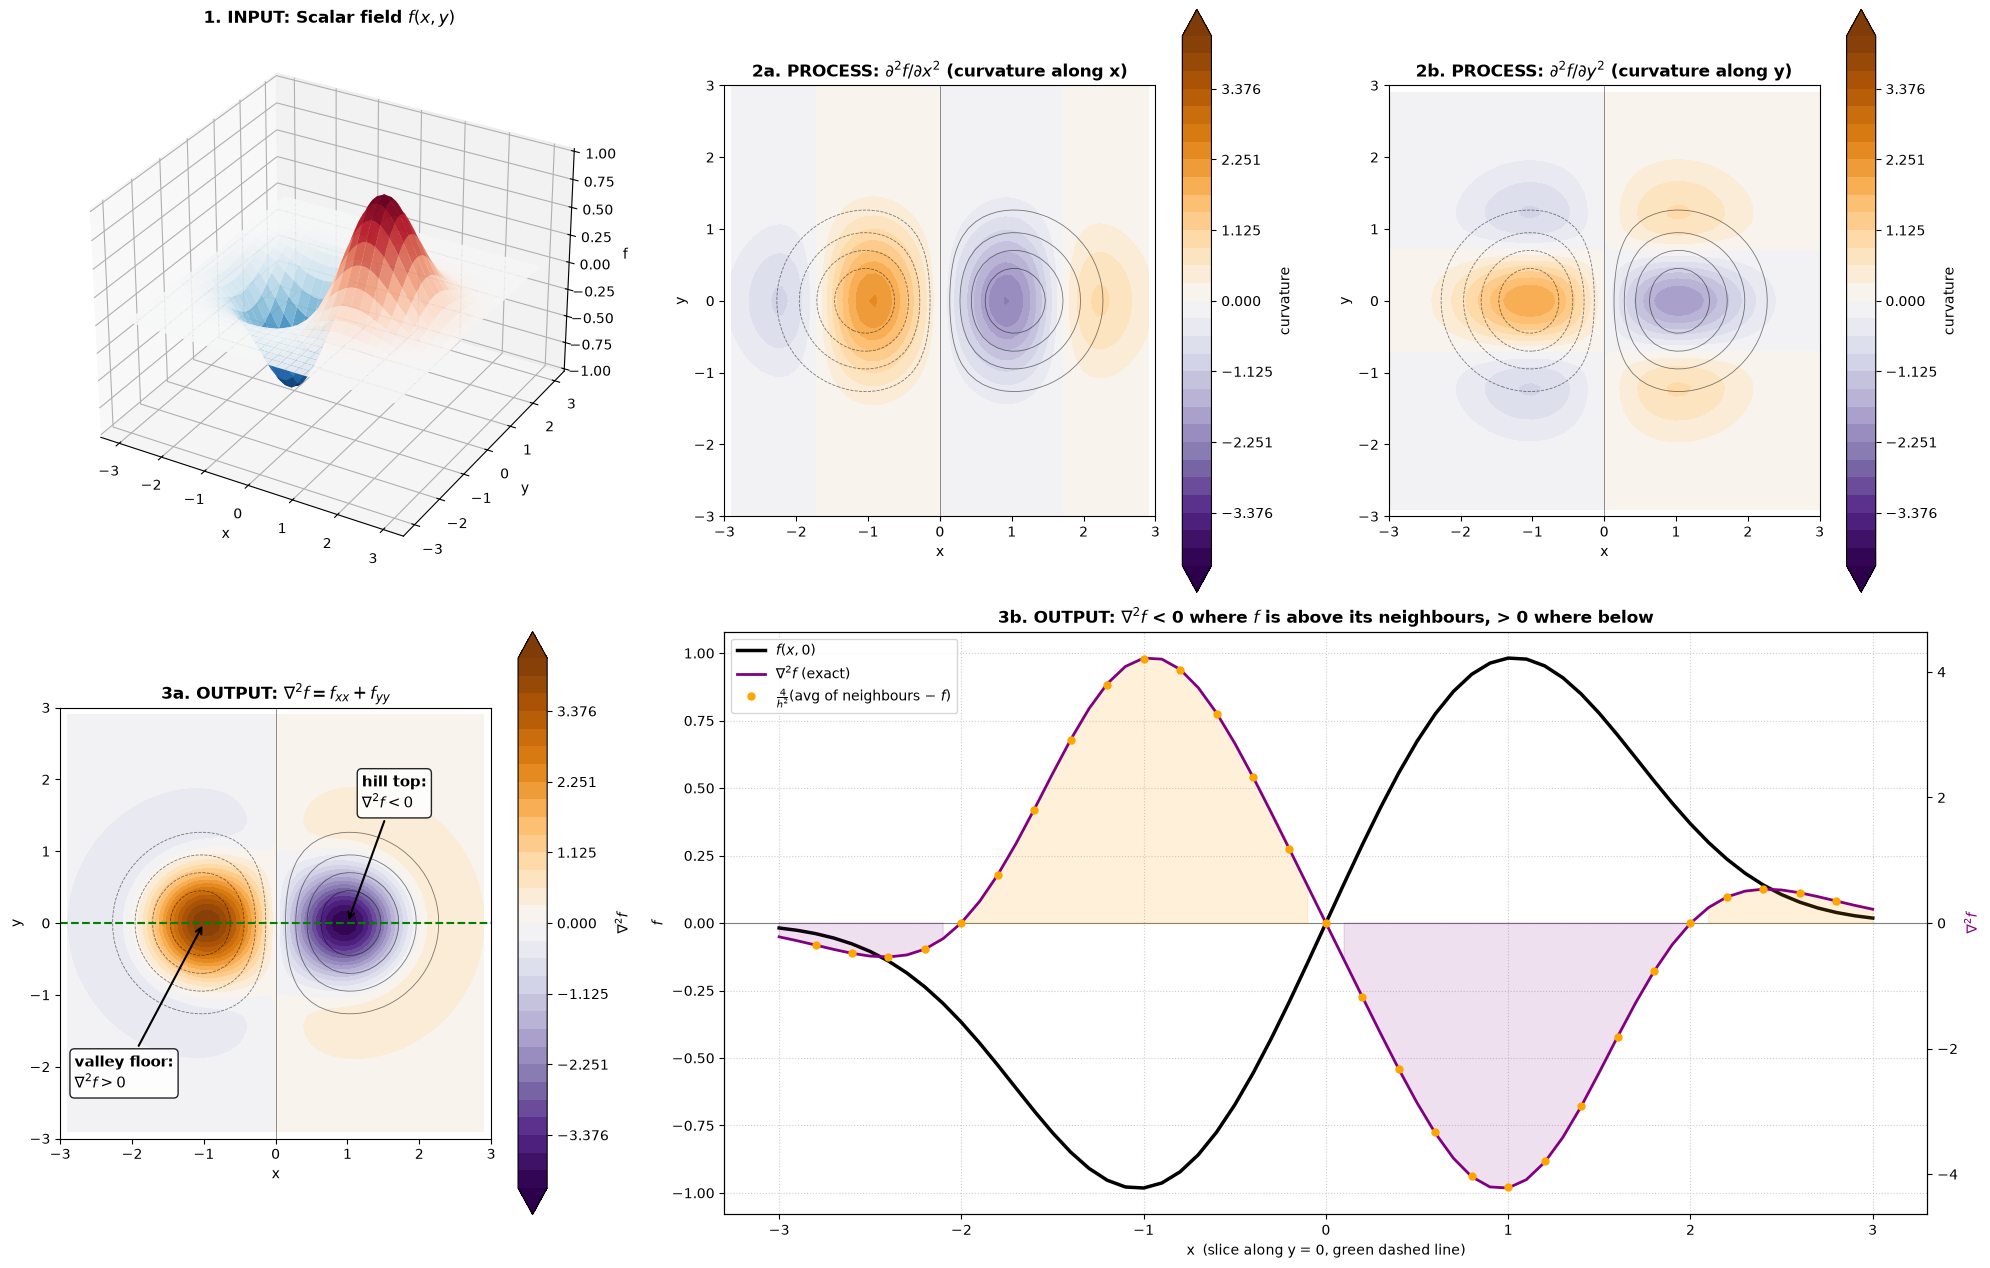

In [5]:
# 5. LAPLACIAN: lap f = d2f/dx2 + d2f/dy2
# INPUT: scalar field f  ->  PROCESS: second partial derivatives  ->  OUTPUT: scalar field lap f

import numpy as np
import matplotlib.pyplot as plt

# --- INPUT: same hill-and-valley field as the gradient section ---
x = np.linspace(-3, 3, 61)
y = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(x, y)
h = x[1] - x[0]
hill = np.exp(-((X - 1)**2 + Y**2))
valley = np.exp(-((X + 1)**2 + Y**2))
f = hill - valley

# --- PROCESS: second derivatives (5-point stencil, interior points) ---
d2f_dx2 = np.full_like(f, np.nan)
d2f_dy2 = np.full_like(f, np.nan)
d2f_dx2[:, 1:-1] = (f[:, 2:] - 2 * f[:, 1:-1] + f[:, :-2]) / h**2
d2f_dy2[1:-1, :] = (f[2:, :] - 2 * f[1:-1, :] + f[:-2, :]) / h**2
lap_f = d2f_dx2 + d2f_dy2

# Analytical Laplacian: for g = exp(-r^2), lap g = (4 r^2 - 4) g
r2_hill = (X - 1)**2 + Y**2
r2_valley = (X + 1)**2 + Y**2
lap_exact = (4 * r2_hill - 4) * hill - (4 * r2_valley - 4) * valley

# Neighbour-average interpretation: (4 / h^2) * (mean of 4 neighbours - f)
neighbour_avg = np.full_like(f, np.nan)
neighbour_avg[1:-1, 1:-1] = (f[1:-1, 2:] + f[1:-1, :-2] + f[2:, 1:-1] + f[:-2, 1:-1]) / 4
lap_from_avg = 4 / h**2 * (neighbour_avg - f)

print("--- LAPLACIAN ---")
print(f"max |lap f numeric - exact|            = {np.nanmax(np.abs(lap_f - lap_exact)):.2e}")
print(f"max |lap f - (4/h^2)(avg_nbrs - f)|    = {np.nanmax(np.abs(lap_f - lap_from_avg)):.2e}")
print(f"lap f at hill top (1, 0)               = {lap_exact[30, 40]:+.3f}  (peak -> negative)")
print(f"lap f at valley floor (-1, 0)          = {lap_exact[30, 20]:+.3f}  (pit  -> positive)")

# --- Visualization ---
fig = plt.figure(figsize=(20, 13))
gs = fig.add_gridspec(2, 3)

# Panel 1: INPUT
ax1 = fig.add_subplot(gs[0, 0], projection='3d')
surf = ax1.plot_surface(X, Y, f, cmap='RdBu_r', edgecolor='none', alpha=0.9)
ax1.set_title('1. INPUT: Scalar field $f(x, y)$', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f')
ax1.view_init(elev=30, azim=-60)

# Panels 2a, 2b: PROCESS (curvature along x and along y)
vmax = np.nanmax(np.abs(lap_exact))
levels = np.linspace(-vmax, vmax, 31)
process = [
    (gs[0, 1], d2f_dx2, r'2a. PROCESS: $\partial^2 f/\partial x^2$ (curvature along x)'),
    (gs[0, 2], d2f_dy2, r'2b. PROCESS: $\partial^2 f/\partial y^2$ (curvature along y)'),
]
for spec, comp, title in process:
    ax = fig.add_subplot(spec)
    cf = ax.contourf(X, Y, comp, levels=levels, cmap='PuOr_r', extend='both')
    ax.contour(X, Y, f, levels=10, colors='k', linewidths=0.6, alpha=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal')
    fig.colorbar(cf, ax=ax, label='curvature')

# Panel 3a: OUTPUT (Laplacian map)
ax4 = fig.add_subplot(gs[1, 0])
cf4 = ax4.contourf(X, Y, lap_f, levels=levels, cmap='PuOr_r', extend='both')
ax4.contour(X, Y, f, levels=10, colors='k', linewidths=0.6, alpha=0.5)
ax4.annotate('hill top:\n$\\nabla^2 f < 0$', xy=(1, 0), xytext=(1.2, 1.6), fontsize=11, fontweight='bold',
             arrowprops=dict(arrowstyle='->', lw=1.5), bbox=dict(boxstyle='round', fc='w', alpha=0.85))
ax4.annotate('valley floor:\n$\\nabla^2 f > 0$', xy=(-1, 0), xytext=(-2.8, -2.3), fontsize=11, fontweight='bold',
             arrowprops=dict(arrowstyle='->', lw=1.5), bbox=dict(boxstyle='round', fc='w', alpha=0.85))
ax4.axhline(0, color='green', ls='--', lw=1.5)
ax4.set_title(r'3a. OUTPUT: $\nabla^2 f = f_{xx} + f_{yy}$', fontsize=12, fontweight='bold')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_aspect('equal')
fig.colorbar(cf4, ax=ax4, label=r'$\nabla^2 f$')

# Panel 3b: OUTPUT (slice along y = 0: f vs. its neighbours)
ax5 = fig.add_subplot(gs[1, 1:])
j0 = np.argmin(np.abs(y))
ax5.plot(x, f[j0], 'k-', lw=2.5, label='$f(x, 0)$')
ax5.set_xlabel('x  (slice along y = 0, green dashed line)')
ax5.set_ylabel('$f$')
ax5.axhline(0, color='gray', lw=0.8)
ax5b = ax5.twinx()
ax5b.plot(x, lap_exact[j0], color='purple', lw=2, label=r'$\nabla^2 f$ (exact)')
ax5b.plot(x[::2], lap_from_avg[j0, ::2], 'o', color='orange', ms=5,
          label=r'$\frac{4}{h^2}$(avg of neighbours $-\ f$)')
ax5b.fill_between(x, lap_exact[j0], 0, where=lap_exact[j0] < 0, color='purple', alpha=0.12)
ax5b.fill_between(x, lap_exact[j0], 0, where=lap_exact[j0] > 0, color='orange', alpha=0.15)
ax5b.set_ylabel(r'$\nabla^2 f$', color='purple')
lines = ax5.get_legend_handles_labels()
lines_b = ax5b.get_legend_handles_labels()
ax5.legend(lines[0] + lines_b[0], lines[1] + lines_b[1], loc='upper left')
ax5.set_title(r'3b. OUTPUT: $\nabla^2 f$ < 0 where $f$ is above its neighbours, > 0 where below',
              fontsize=12, fontweight='bold')
ax5.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Vector Identities

| Identity | Meaning |
|---|---|
| $\nabla\times(\nabla f) = \mathbf 0$ | A gradient field has no rotation (it is *conservative*), because mixed partials are equal: $\partial_x\partial_y f = \partial_y\partial_x f$. |
| $\nabla\cdot(\nabla\times\mathbf A) = 0$ | A curl field has no sources or sinks: it only circulates. |
| $\nabla\cdot(\nabla f) = \nabla^2 f$ | The Laplacian is the divergence of the gradient. |

Each row of the figure checks one identity numerically: **INPUT** field, **PROCESS** (the derivatives that combine), **OUTPUT** (the result). For the first two, the central-difference operators commute exactly, so the result is zero to machine precision. For a 2D example of the second identity, take $\mathbf A = (0, 0, \psi)$, so that $\nabla\times\mathbf A = (\partial_y\psi,\ -\partial_x\psi,\ 0)$.

--- VECTOR IDENTITIES ---
(i)   max |curl(grad f)|          = 1.03e-14   (zero to machine precision)
(ii)  max |div(curl A)|           = 1.03e-14   (zero to machine precision)
(iii) max |div(grad f) - lap f|   = 7.36e-02   (discretisation error, h = 0.10)


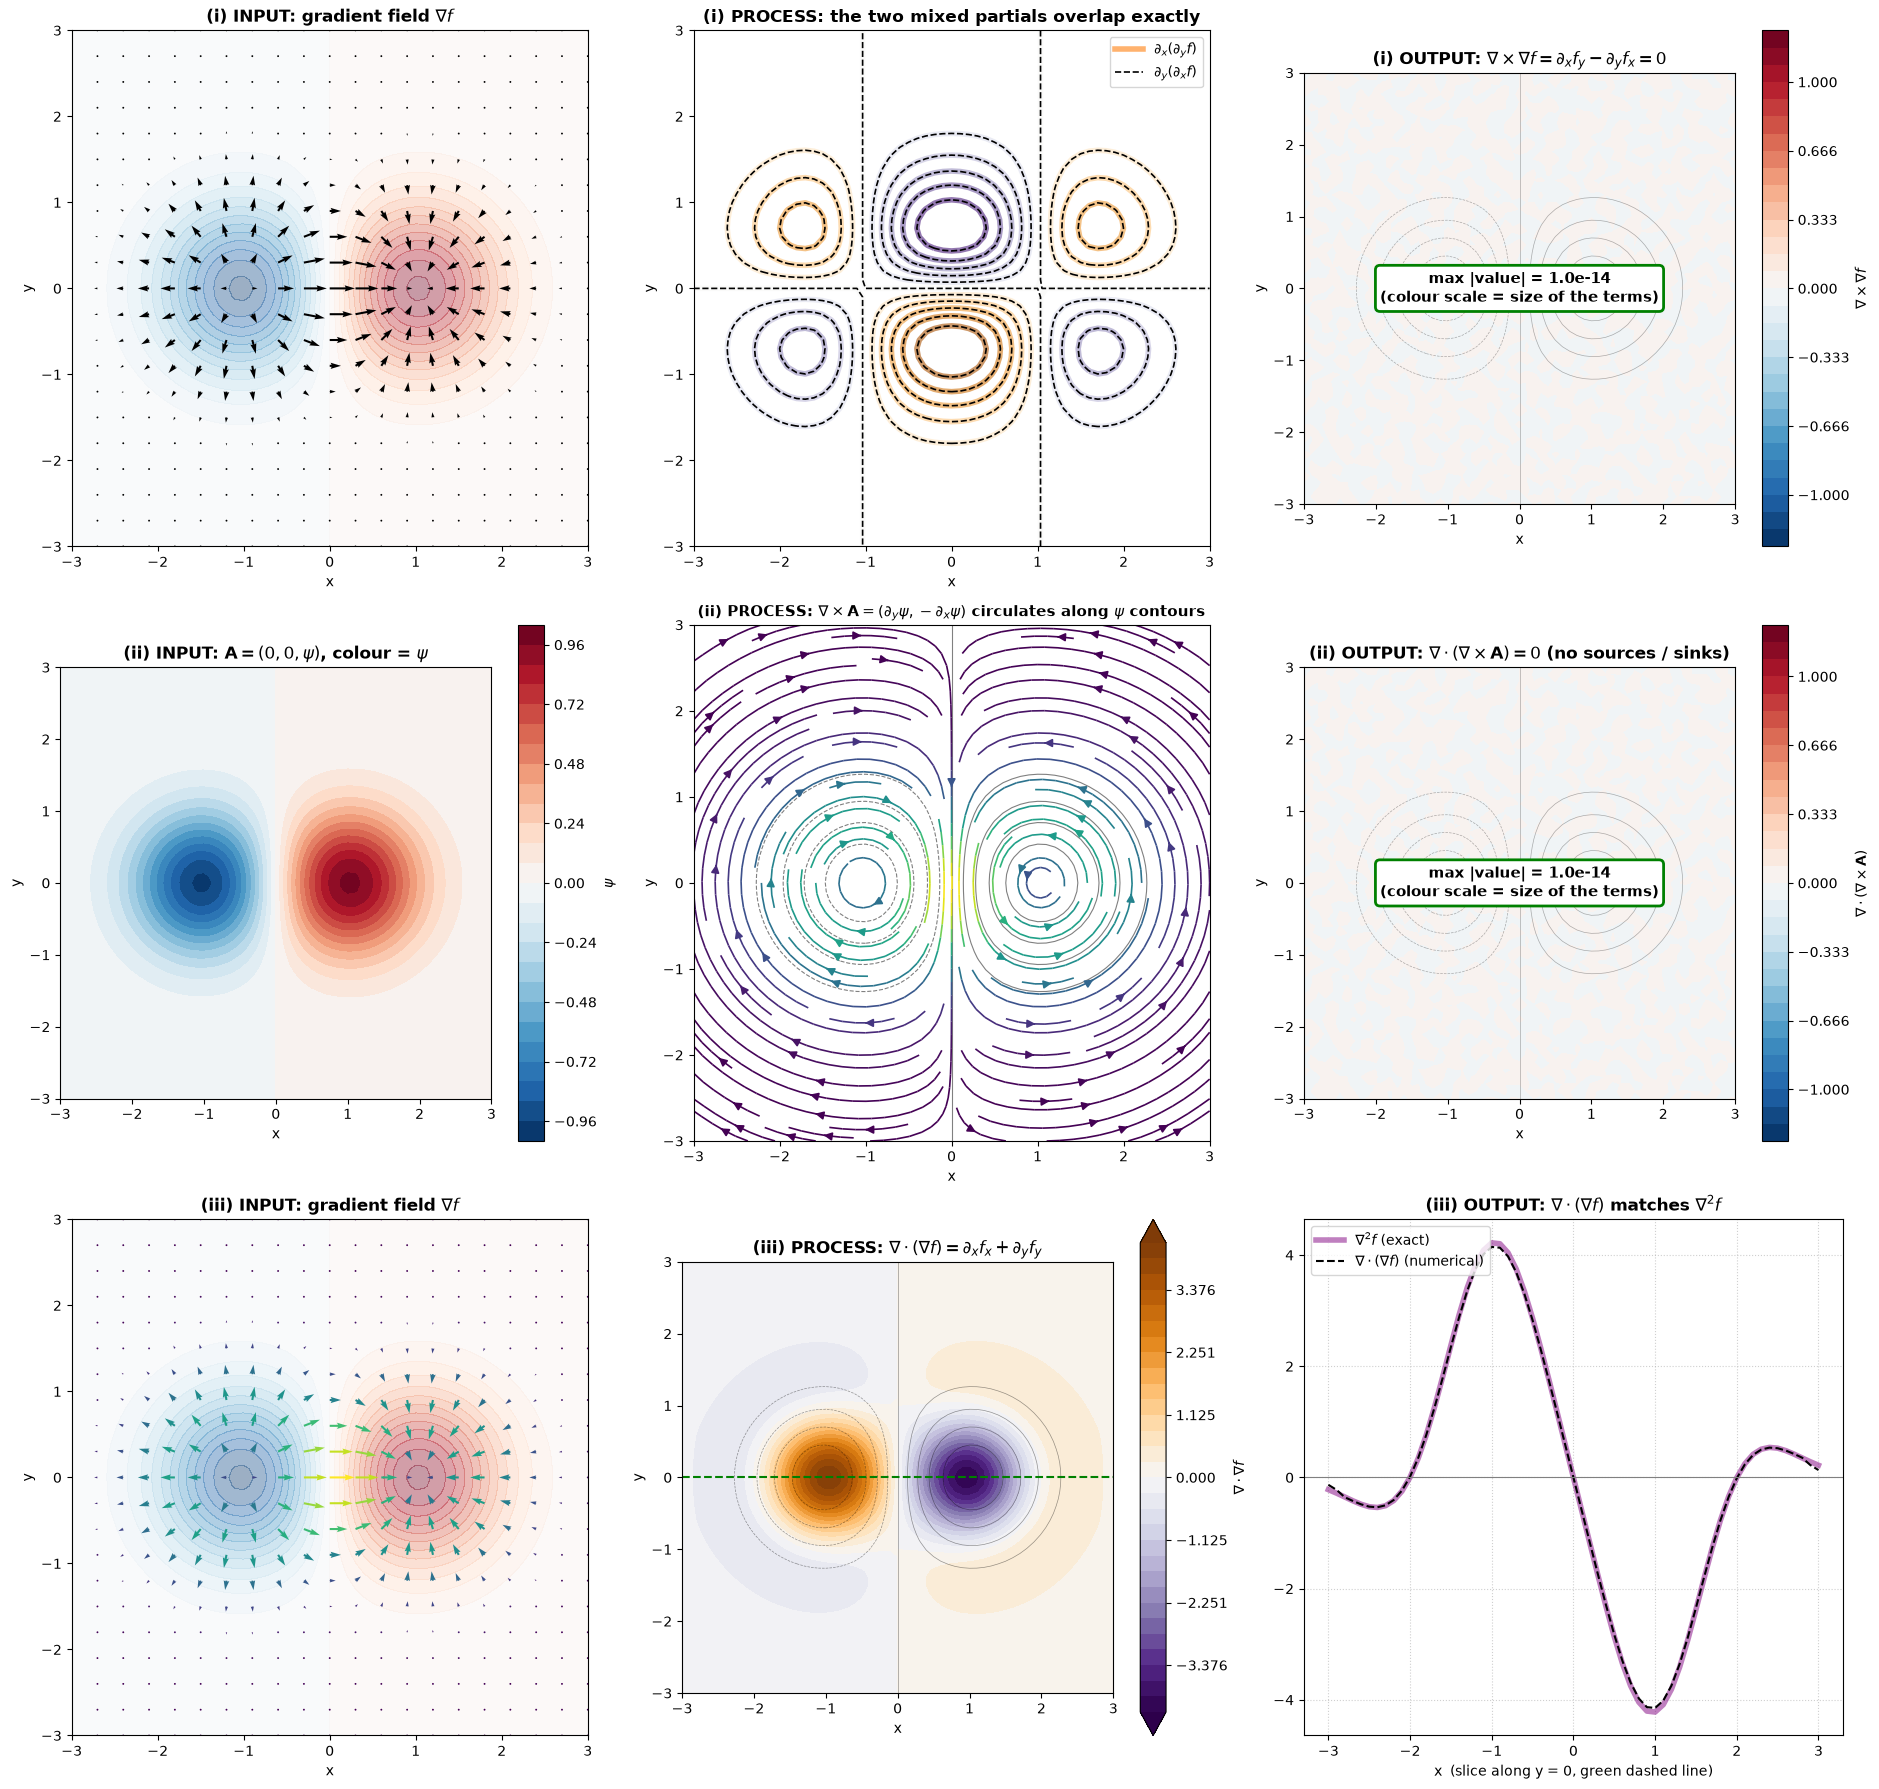

In [6]:
# 6. VECTOR IDENTITIES
#   (i)   curl(grad f) = 0
#   (ii)  div(curl A)  = 0
#   (iii) div(grad f)  = lap f

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

x = np.linspace(-3, 3, 61)
y = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(x, y)
hill = np.exp(-((X - 1)**2 + Y**2))
valley = np.exp(-((X + 1)**2 + Y**2))
f = hill - valley


def ddx(a):
    return np.gradient(a, x, axis=1)


def ddy(a):
    return np.gradient(a, y, axis=0)


# (i) curl(grad f): the two mixed partials cancel
fx, fy = ddx(f), ddy(f)
d_fy_dx = ddx(fy)
d_fx_dy = ddy(fx)
curl_grad = d_fy_dx - d_fx_dy

# (ii) div(curl A) with A = (0, 0, psi): curl A = (dpsi/dy, -dpsi/dx)
psi = f
Fx, Fy = ddy(psi), -ddx(psi)
dFx_dx = ddx(Fx)
dFy_dy = ddy(Fy)
div_curl = dFx_dx + dFy_dy

# (iii) div(grad f) vs the exact Laplacian
div_grad = ddx(fx) + ddy(fy)
lap_exact = (4 * ((X - 1)**2 + Y**2) - 4) * hill - (4 * ((X + 1)**2 + Y**2) - 4) * valley

print("--- VECTOR IDENTITIES ---")
print(f"(i)   max |curl(grad f)|          = {np.max(np.abs(curl_grad)):.2e}   (zero to machine precision)")
print(f"(ii)  max |div(curl A)|           = {np.max(np.abs(div_curl)):.2e}   (zero to machine precision)")
inner = np.s_[2:-2, 2:-2]
print(f"(iii) max |div(grad f) - lap f|   = {np.max(np.abs(div_grad - lap_exact)[inner]):.2e}   "
      f"(discretisation error, h = {x[1] - x[0]:.2f})")


def zero_panel(ax, values, ref, title, label):
    # Plot a result on the same colour scale as the terms that produced it, so 'zero' looks blank.
    vmax = np.abs(ref).max()
    cf = ax.contourf(X, Y, values, levels=np.linspace(-vmax, vmax, 31), cmap='RdBu_r')
    ax.contour(X, Y, f, levels=10, colors='k', linewidths=0.5, alpha=0.3)
    ax.text(0, 0, f'max |value| = {np.max(np.abs(values)):.1e}\n(colour scale = size of the terms)',
            ha='center', va='center', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', fc='w', ec='green', lw=2))
    ax.set_title(title, fontsize=12, fontweight='bold')
    fig.colorbar(cf, ax=ax, label=label)


fig, axes = plt.subplots(3, 3, figsize=(19, 18))
s = 3
Xs, Ys = X[::s, ::s], Y[::s, ::s]

# --- Row (i): curl(grad f) = 0 ---
ax = axes[0, 0]
ax.contourf(X, Y, f, levels=30, cmap='RdBu_r', alpha=0.4)
ax.quiver(Xs, Ys, fx[::s, ::s], fy[::s, ::s], color='k', scale_units='xy', scale=5, width=0.004)
ax.set_title(r'(i) INPUT: gradient field $\nabla f$', fontsize=12, fontweight='bold')

ax = axes[0, 1]
lv = np.linspace(-np.abs(d_fy_dx).max(), np.abs(d_fy_dx).max(), 13)
ax.contour(X, Y, d_fy_dx, levels=lv, cmap='PuOr_r', linewidths=4, alpha=0.6)
ax.contour(X, Y, d_fx_dy, levels=lv, colors='k', linewidths=1.2, linestyles='--')
ax.legend(handles=[Line2D([], [], color='tab:orange', lw=4, alpha=0.6, label=r'$\partial_x(\partial_y f)$'),
                   Line2D([], [], color='k', lw=1.2, ls='--', label=r'$\partial_y(\partial_x f)$')],
          loc='upper right')
ax.set_title('(i) PROCESS: the two mixed partials overlap exactly', fontsize=12, fontweight='bold')

zero_panel(axes[0, 2], curl_grad, d_fy_dx,
           r'(i) OUTPUT: $\nabla\times\nabla f = \partial_x f_y - \partial_y f_x = 0$', r'$\nabla\times\nabla f$')

# --- Row (ii): div(curl A) = 0 ---
ax = axes[1, 0]
cf = ax.contourf(X, Y, psi, levels=30, cmap='RdBu_r')
ax.set_title(r'(ii) INPUT: $\mathbf{A} = (0, 0, \psi)$, colour = $\psi$', fontsize=12, fontweight='bold')
fig.colorbar(cf, ax=ax, label=r'$\psi$')

ax = axes[1, 1]
ax.contour(X, Y, psi, levels=12, colors='gray', linewidths=0.8)
speed = np.hypot(Fx, Fy)
ax.streamplot(x, y, Fx, Fy, color=speed, cmap='viridis', density=1.3, linewidth=1.2, arrowsize=1.2)
ax.set_title(r'(ii) PROCESS: $\nabla\times\mathbf{A} = (\partial_y\psi, -\partial_x\psi)$ circulates along $\psi$ contours',
             fontsize=11, fontweight='bold')

zero_panel(axes[1, 2], div_curl, dFx_dx,
           r'(ii) OUTPUT: $\nabla\cdot(\nabla\times\mathbf{A}) = 0$ (no sources / sinks)',
           r'$\nabla\cdot(\nabla\times\mathbf{A})$')

# --- Row (iii): div(grad f) = lap f ---
ax = axes[2, 0]
ax.contourf(X, Y, f, levels=30, cmap='RdBu_r', alpha=0.4)
mag = np.hypot(fx, fy)
ax.quiver(Xs, Ys, fx[::s, ::s], fy[::s, ::s], mag[::s, ::s], cmap='viridis', scale_units='xy', scale=5, width=0.004)
ax.set_title(r'(iii) INPUT: gradient field $\nabla f$', fontsize=12, fontweight='bold')

ax = axes[2, 1]
vmax = np.abs(lap_exact).max()
cf = ax.contourf(X, Y, div_grad, levels=np.linspace(-vmax, vmax, 31), cmap='PuOr_r', extend='both')
ax.contour(X, Y, f, levels=10, colors='k', linewidths=0.5, alpha=0.4)
ax.axhline(0, color='green', ls='--', lw=1.5)
ax.set_title(r'(iii) PROCESS: $\nabla\cdot(\nabla f) = \partial_x f_x + \partial_y f_y$', fontsize=12, fontweight='bold')
fig.colorbar(cf, ax=ax, label=r'$\nabla\cdot\nabla f$')

ax = axes[2, 2]
j0 = np.argmin(np.abs(y))
ax.plot(x, lap_exact[j0], color='purple', lw=4, alpha=0.5, label=r'$\nabla^2 f$ (exact)')
ax.plot(x, div_grad[j0], 'k--', lw=1.5, label=r'$\nabla\cdot(\nabla f)$ (numerical)')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('x  (slice along y = 0, green dashed line)')
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_title(r'(iii) OUTPUT: $\nabla\cdot(\nabla f)$ matches $\nabla^2 f$', fontsize=12, fontweight='bold')

for ax in axes.flat:
    if ax is not axes[2, 2]:
        ax.set_aspect('equal')
        ax.set_xlabel('x')
        ax.set_ylabel('y')

plt.tight_layout()
plt.show()